## Choose either dataset to test binary classification. Create a 4-layer Dense network, 
## test with minimum neurons (64, 32, 16, 1), then Increase Units in Dense layers and 
## also Increase Number of Layers add BatchNormalization to Layers add Dropout after Layers.

# Titanic Dataset
https://www.kaggle.com/datasets/vicsuperman/prediction-of-music-genre?select=music_genre.csv

In [42]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split

print("ok")

ok


In [43]:
data = pd.read_csv("music_genre.csv")
data.head(5)

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
0,32894.0,Röyksopp,Röyksopp's Night Out,27.0,0.00468,0.652,-1.0,0.941,0.79200,A#,0.115,-5.201,Minor,0.0748,100.889,4-Apr,0.759,Electronic
1,46652.0,Thievery Corporation,The Shining Path,31.0,0.01270,0.622,218293.0,0.890,0.95000,D,0.124,-7.043,Minor,0.0300,115.00200000000001,4-Apr,0.531,Electronic
2,30097.0,Dillon Francis,Hurricane,28.0,0.00306,0.620,215613.0,0.755,0.01180,G#,0.534,-4.617,Major,0.0345,127.994,4-Apr,0.333,Electronic
3,62177.0,Dubloadz,Nitro,34.0,0.02540,0.774,166875.0,0.700,0.00253,C#,0.157,-4.498,Major,0.2390,128.014,4-Apr,0.270,Electronic
4,24907.0,What So Not,Divide & Conquer,32.0,0.00465,0.638,222369.0,0.587,0.90900,F#,0.157,-6.266,Major,0.0413,145.036,4-Apr,0.323,Electronic


In [44]:
# tempo is read as string not float
print(data['tempo'].dtype)
data['tempo'] = pd.to_numeric(data['tempo'], errors='coerce')
print(data['tempo'].dtype)

object
float64


In [45]:
data.drop(['instance_id', 'artist_name', 'track_name', 'obtained_date', 'duration_ms'] , axis = 1 , inplace = True)

In [46]:
data.isnull().sum()

popularity             5
acousticness           5
danceability           5
energy                 5
instrumentalness       5
key                    5
liveness               5
loudness               5
mode                   5
speechiness            5
tempo               4985
valence                5
music_genre            5
dtype: int64

In [47]:
# data = data.fillna(data.median(numeric_only=True))

In [48]:
data.dropna(inplace = True)

In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45020 entries, 0 to 50004
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   popularity        45020 non-null  float64
 1   acousticness      45020 non-null  float64
 2   danceability      45020 non-null  float64
 3   energy            45020 non-null  float64
 4   instrumentalness  45020 non-null  float64
 5   key               45020 non-null  object 
 6   liveness          45020 non-null  float64
 7   loudness          45020 non-null  float64
 8   mode              45020 non-null  object 
 9   speechiness       45020 non-null  float64
 10  tempo             45020 non-null  float64
 11  valence           45020 non-null  float64
 12  music_genre       45020 non-null  object 
dtypes: float64(10), object(3)
memory usage: 4.8+ MB


In [50]:
# Label encode Object Datatypes 
data_types_dict = dict(data.dtypes)
# Keep track Mappings Column name to LabelEncoders
Label_encoder_collection = {}
for col_name , data_type in data_types_dict.items():
    if data_type == 'object':
        Le = LabelEncoder()
        data[col_name] = Le.fit_transform(data[col_name])
        Label_encoder_collection[col_name] = Le 

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45020 entries, 0 to 50004
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   popularity        45020 non-null  float64
 1   acousticness      45020 non-null  float64
 2   danceability      45020 non-null  float64
 3   energy            45020 non-null  float64
 4   instrumentalness  45020 non-null  float64
 5   key               45020 non-null  int64  
 6   liveness          45020 non-null  float64
 7   loudness          45020 non-null  float64
 8   mode              45020 non-null  int64  
 9   speechiness       45020 non-null  float64
 10  tempo             45020 non-null  float64
 11  valence           45020 non-null  float64
 12  music_genre       45020 non-null  int64  
dtypes: float64(10), int64(3)
memory usage: 4.8 MB


In [51]:
for col_name, label_encoder in Label_encoder_collection.items():
    print(f"Label Encoding mapping for column: {col_name}")
    # Get the mapping (original labels to encoded integers)
    mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
    print(mapping)
    print("-" * 30)

Label Encoding mapping for column: key
{'A': 0, 'A#': 1, 'B': 2, 'C': 3, 'C#': 4, 'D': 5, 'D#': 6, 'E': 7, 'F': 8, 'F#': 9, 'G': 10, 'G#': 11}
------------------------------
Label Encoding mapping for column: mode
{'Major': 0, 'Minor': 1}
------------------------------
Label Encoding mapping for column: music_genre
{'Alternative': 0, 'Anime': 1, 'Blues': 2, 'Classical': 3, 'Country': 4, 'Electronic': 5, 'Hip-Hop': 6, 'Jazz': 7, 'Rap': 8, 'Rock': 9}
------------------------------


In [52]:
num_genres = len(Label_encoder_collection['music_genre'].classes_)
num_genres

10

In [53]:
data.head(5)

,popularity,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,music_genre
0,27.0,0.00468,0.652,0.941,0.79200,1,0.115,-5.201,1,0.0748,100.889,0.759,5
1,31.0,0.01270,0.622,0.890,0.95000,5,0.124,-7.043,1,0.0300,115.002,0.531,5
2,28.0,0.00306,0.620,0.755,0.01180,11,0.534,-4.617,0,0.0345,127.994,0.333,5
3,34.0,0.02540,0.774,0.700,0.00253,4,0.157,-4.498,0,0.2390,128.014,0.270,5
4,32.0,0.00465,0.638,0.587,0.90900,9,0.157,-6.266,0,0.0413,145.036,0.323,5


In [54]:
X = data.iloc[: , :-1].values.astype(np.float32)
Y = data.iloc[: , -1].values.astype(int)

In [55]:
X

array([[2.70000e+01, 4.68000e-03, 6.52000e-01, ..., 7.48000e-02,
        1.00889e+02, 7.59000e-01],
       [3.10000e+01, 1.27000e-02, 6.22000e-01, ..., 3.00000e-02,
        1.15002e+02, 5.31000e-01],
       [2.80000e+01, 3.06000e-03, 6.20000e-01, ..., 3.45000e-02,
        1.27994e+02, 3.33000e-01],
       ...,
       [5.10000e+01, 5.97000e-03, 6.93000e-01, ..., 1.46000e-01,
        1.31079e+02, 3.95000e-01],
       [6.50000e+01, 8.31000e-02, 7.82000e-01, ..., 4.41000e-02,
        7.58860e+01, 3.54000e-01],
       [6.70000e+01, 1.02000e-01, 8.62000e-01, ..., 1.01000e-01,
        9.92010e+01, 7.65000e-01]], dtype=float32)

In [56]:
Y

array([5, 5, 5, ..., 6, 6, 6])

In [57]:
Xtrain , Xtest , Ytrain , Ytest = train_test_split(X, Y, test_size = 0.3, random_state = 333)

In [58]:
# normalizare
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain)
Xtest = scaler.transform(Xtest)

In [59]:
input_shape = Xtrain.shape[1]

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(input_shape,)))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(64, activation='relu'))
model.add(tf.keras.layers.Dense(32, activation='relu'))
model.add(tf.keras.layers.Dense(num_genres, activation='softmax'))  # pentru clasificare multi-class

# print summary to undertstand your neural network flow
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,330 (48.16 KB)

 Trainable params: 12,330 (48.16 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
Optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
model.compile(Optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])

In [61]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest), epochs=20)

Epoch 1/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4683 - loss: 1.4158 - val_accuracy: 0.5259 - val_loss: 1.2603
Epoch 2/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5299 - loss: 1.2394 - val_accuracy: 0.5421 - val_loss: 1.1965
Epoch 3/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5416 - loss: 1.1910 - val_accuracy: 0.5495 - val_loss: 1.1576
Epoch 4/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5518 - loss: 1.1718 - val_accuracy: 0.5652 - val_loss: 1.1375
Epoch 5/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5527 - loss: 1.1689 - val_accuracy: 0.5528 - val_loss: 1.1551
Epoch 6/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5563 - loss: 1.1512 - val_accuracy: 0.5518 - val_loss: 1.1703
Epoch 7/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5540 - loss: 1.1572 - val_accuracy: 0.5499 - val_loss: 1.1836
Epoch 8/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5635 - loss: 1.1501 - val_accuracy: 0.

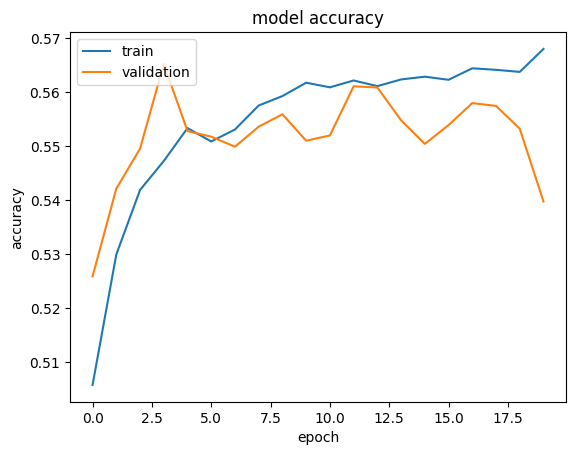

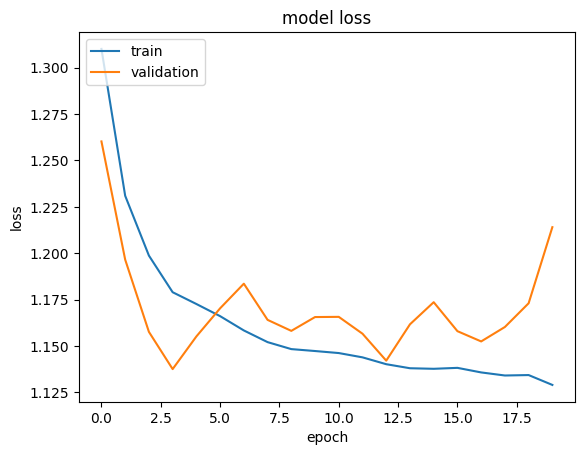

In [62]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [63]:
predictions = np.argmax(model.predict(Xtest), axis=1)

423/423 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


In [64]:
from sklearn.metrics import accuracy_score , confusion_matrix
accuracy_score(Ytest , predictions) # Accuracy Seems good

0.5397601066192803

In [65]:
confusion_matrix(Ytest , predictions)

array([[ 376,   35,   37,    3,  178,   64,   25,  111,  198,  359],
       [  30,  886,  144,  136,   54,   57,    0,   57,    2,   11],
       [  37,  138,  663,   10,  135,   43,    2,  188,   10,   80],
       [  27,   37,   46, 1056,    5,   26,    0,  111,    0,    9],
       [  88,   47,  109,    1,  671,   31,    1,   80,   37,  278],
       [  48,  103,   88,    7,   49,  710,    1,  246,   50,   46],
       [  21,    1,    0,    0,   17,   28,   38,   22, 1178,   83],
       [  23,   15,  160,   66,   79,  109,    7,  781,   27,   92],
       [  21,    2,    0,    0,    9,   13,    9,   13, 1131,  158],
       [  67,    4,    6,    2,   72,    6,    1,   27,  163,  978]])

In [66]:
from sklearn.metrics import classification_report 
print(classification_report(Ytest, predictions, zero_division=0))

              precision    recall  f1-score   support

           0       0.51      0.27      0.35      1386
           1       0.70      0.64      0.67      1377
           2       0.53      0.51      0.52      1306
           3       0.82      0.80      0.81      1317
           4       0.53      0.50      0.51      1343
           5       0.65      0.53      0.58      1348
           6       0.45      0.03      0.05      1388
           7       0.48      0.57      0.52      1359
           8       0.40      0.83      0.54      1356
           9       0.47      0.74      0.57      1326

    accuracy                           0.54     13506
   macro avg       0.55      0.54      0.51     13506
weighted avg       0.55      0.54      0.51     13506



In [67]:
# we will try to improve our model's performance 
# ----------- Add class weights when Data is Imbalanced -----------------------
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(class_weight = 'balanced',  classes = np.unique(Ytrain), y=Ytrain)

model_class_weights = {}
for e , weight in enumerate(class_weights):
    model_class_weights[e] = weight

In [68]:
model_class_weights

{0: 1.0136378256674172,
 1: 1.0100641025641026,
 2: 0.9960176991150442,
 3: 0.990072258875275,
 4: 1.0026726057906459,
 5: 1.0107119948685055,
 6: 1.0061941251596425,
 7: 0.9966476913345984,
 8: 1.0010800508259212,
 9: 0.9741576506955177}

In [69]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=20, class_weight=model_class_weights)

Epoch 1/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5662 - loss: 1.1228 - val_accuracy: 0.5559 - val_loss: 1.1666
Epoch 2/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5690 - loss: 1.1240 - val_accuracy: 0.5586 - val_loss: 1.1534
Epoch 3/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5584 - loss: 1.1347 - val_accuracy: 0.5575 - val_loss: 1.1671
Epoch 4/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5709 - loss: 1.1138 - val_accuracy: 0.5570 - val_loss: 1.1707
Epoch 5/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5643 - loss: 1.1356 - val_accuracy: 0.5449 - val_loss: 1.1789
Epoch 6/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5693 - loss: 1.1296 - val_accuracy: 0.5555 - val_loss: 1.1660
Epoch 7/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5694 - loss: 1.1137 - val_accuracy: 0.5507 - val_loss: 1.1757
Epoch 8/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5692 - loss: 1.1171 - val_accuracy: 0.

In [70]:
predictions = np.argmax(model.predict(Xtest), axis=1)

423/423 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


In [71]:
from sklearn.metrics import confusion_matrix
confusion_matrix(Ytest, predictions)

array([[ 437,   31,   11,   10,  165,   51,  145,   89,   69,  378],
       [  35, 1065,   46,  102,   54,   44,    1,   23,    1,    6],
       [  60,  206,  441,   34,  133,   69,    3,  266,    5,   89],
       [  34,   59,   10, 1103,    1,   22,    0,   81,    0,    7],
       [ 115,   60,   36,    1,  654,   24,   30,   96,   17,  310],
       [  88,  122,   47,   12,   47,  672,   17,  255,   37,   51],
       [  32,    2,    0,    0,    5,    9,  408,   20,  828,   84],
       [  84,   23,   53,   89,   61,  115,   28,  822,   10,   74],
       [  54,    1,    1,    0,    2,    6,  317,   10,  819,  146],
       [ 132,    5,    0,    2,   43,    7,   32,   30,  117,  958]])

In [72]:
Xtrain , Xtest , Ytrain , Ytest = train_test_split(X, Y, test_size = 0.3, random_state = 333)

In [73]:
# normalizare
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain)
Xtest = scaler.transform(Xtest)

In [74]:
# Increase Units in Dense layers and Also Increase Number of Layers 
# Add BatchNormalization to Layers 
# Add Dropout after Layers 

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(input_shape,)))

model.add(tf.keras.layers.Dense(256 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(128 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(64 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.2))

model.add(tf.keras.layers.Dense(num_genres , activation='softmax'))

# model = tf.keras.models.Sequential()
# model.add(tf.keras.Input(shape=(input_shape,)))
# model.add(tf.keras.layers.Dense(128, activation='relu'))
# model.add(tf.keras.layers.Dense(64, activation='relu'))
# model.add(tf.keras.layers.BatchNormalization())
# model.add(tf.keras.layers.Dense(32, activation='relu'))
# model.add(tf.keras.layers.Dense(num_genres, activation='softmax'))  # pentru clasificare multi-class

# print summary to undertstand your neural network flow
# model.summary()

Optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
# Optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)
model.compile(Optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])

history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=80)

Epoch 1/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.3920 - loss: 1.7601 - val_accuracy: 0.5483 - val_loss: 1.1980
Epoch 2/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4972 - loss: 1.3498 - val_accuracy: 0.5531 - val_loss: 1.1712
Epoch 3/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5108 - loss: 1.2919 - val_accuracy: 0.5572 - val_loss: 1.1440
Epoch 4/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5232 - loss: 1.2536 - val_accuracy: 0.5634 - val_loss: 1.1317
Epoch 5/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5220 - loss: 1.2590 - val_accuracy: 0.5636 - val_loss: 1.1219
Epoch 6/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5314 - loss: 1.2334 - val_accuracy: 0.5672 - val_loss: 1.1191
Epoch 7/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5345 - loss: 1.2260 - val_accuracy: 0.5668 - val_loss: 1.1100
Epoch 8/80
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5395 - loss: 1.2116 - val_accuracy: 0.

In [75]:
Optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
model.compile(Optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])

In [76]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=20)

Epoch 1/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.5203 - loss: 1.2581 - val_accuracy: 0.5586 - val_loss: 1.1334
Epoch 2/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5302 - loss: 1.2308 - val_accuracy: 0.5588 - val_loss: 1.1337
Epoch 3/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5297 - loss: 1.2341 - val_accuracy: 0.5599 - val_loss: 1.1382
Epoch 4/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5320 - loss: 1.2336 - val_accuracy: 0.5646 - val_loss: 1.1165
Epoch 5/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5350 - loss: 1.2272 - val_accuracy: 0.5626 - val_loss: 1.1316
Epoch 6/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5384 - loss: 1.2091 - val_accuracy: 0.5709 - val_loss: 1.1028
Epoch 7/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5337 - loss: 1.2167 - val_accuracy: 0.5642 - val_loss: 1.1045
Epoch 8/20
985/985 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5400 - loss: 1.2035 - val_accuracy: 0.

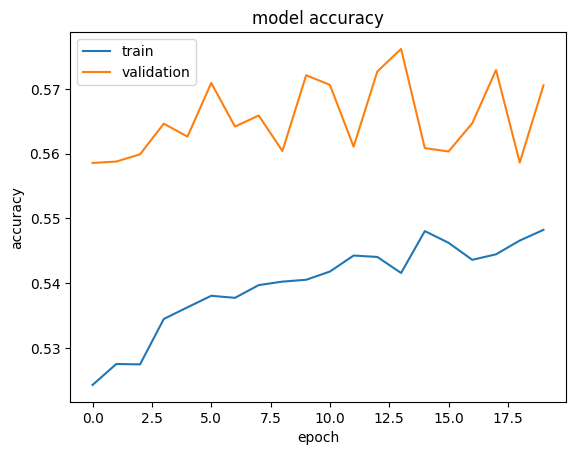

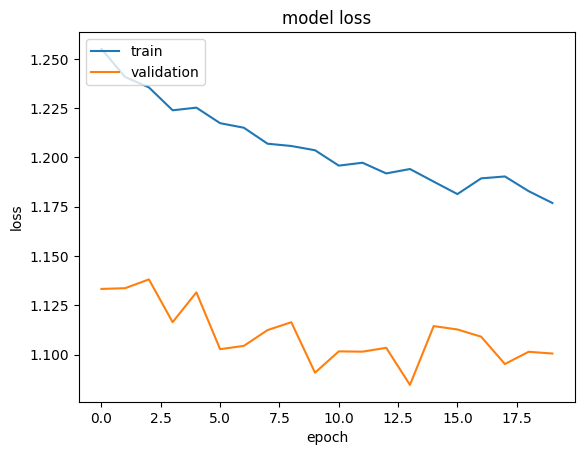

In [77]:
#  "Accuracy Plot"
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# We see graphs converging better compared to previous implementation

In [78]:
# collect predictions 
predictions = np.argmax(model.predict(Xtest), axis=1)

423/423 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step   


In [79]:
# Check Accuracy
accuracy_score(Ytest , predictions) # Accuracy is good

0.5705612320450171

In [80]:
# We don't see the problem of predicting everything as class 0
confusion_matrix(Ytest , predictions)

array([[ 504,   16,   43,   10,  211,   88,  130,   73,   56,  255],
       [  42,  928,  165,  129,   56,   31,    1,   20,    0,    5],
       [  48,   73,  834,   25,  129,   55,    2,   74,    3,   63],
       [  29,   27,   34, 1154,    4,   11,    0,   51,    0,    7],
       [  94,    9,  101,    2,  825,   57,   24,   38,   10,  183],
       [  69,   95,  118,   20,   47,  781,   26,  147,   14,   31],
       [  44,    0,    2,    0,    6,   34,  579,   18,  639,   66],
       [  61,    6,  232,  124,   94,  197,   21,  587,    5,   32],
       [  55,    0,    2,    0,   12,   15,  436,   15,  673,  148],
       [ 116,    3,   13,    5,  151,   27,   34,   56,   80,  841]])

In [81]:
print(classification_report(Ytest, predictions))

              precision    recall  f1-score   support

           0       0.47      0.36      0.41      1386
           1       0.80      0.67      0.73      1377
           2       0.54      0.64      0.59      1306
           3       0.79      0.88      0.83      1317
           4       0.54      0.61      0.57      1343
           5       0.60      0.58      0.59      1348
           6       0.46      0.42      0.44      1388
           7       0.54      0.43      0.48      1359
           8       0.45      0.50      0.47      1356
           9       0.52      0.63      0.57      1326

    accuracy                           0.57     13506
   macro avg       0.57      0.57      0.57     13506
weighted avg       0.57      0.57      0.57     13506

